# Commercial Fleet Route Optimization
This notebook parses the SUMO network file (`osm.net.xml.gz`), builds a NetworkX directed graph restricted to roads a delivery van can use (largest strongly connected component), and computes candidate paths with Yen's $k$-shortest simple paths algorithm.

**Outputs for the QUBO step:** `paths[d]`, `C[(d,p)]` (free-flow seconds), `E[(d,p)]` (edge-ID sets), `S[(a,b)]` (shared-edge counts between routes).

In [24]:
# Install required libraries if not already installed
%pip install sumolib networkx matplotlib qiskit qiskit-algorithms qiskit-aer-gpu pandas

Note: you may need to restart the kernel to use updated packages.


In [25]:
import math
import os
import random
import sys
import time
from itertools import combinations, islice
from types import SimpleNamespace

import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import pandas as pd
from scipy.optimize import minimize
import sumolib

from qiskit import transpile
from qiskit.circuit.library import qaoa_ansatz
from qiskit.primitives import StatevectorEstimator
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error
from qiskit_aer.primitives import EstimatorV2 as AerEstimator, SamplerV2 as AerSampler
from qiskit_algorithms.optimizers import SPSA

if "src" not in sys.path:
    sys.path.insert(0, "src")

from fleetopt.hamiltonian import (
    bitstring_to_assignment,
    ising_to_cost_hamiltonian,
    qubo_to_ising,
)
from fleetopt.two_depot import build_tour_qubo, decode_tour, max_tour_cost, total_distance

## 1. Build the road graph
Only vehicle-accessible edges are kept (`allows("delivery")`), zero-speed edges are skipped, parallel edges keep the faster one, and the graph is reduced to its largest strongly connected component so every depot→destination path exists.

In [26]:
net_path = os.path.join(os.curdir, "SUMO_GEN_SCENARIO", "osm.net.xml.gz")
assert os.path.exists(net_path), f"File not found: {net_path}"
print(f"Found network file at: {net_path}")

net = sumolib.net.readNet(net_path)

G = nx.DiGraph()
for edge in net.getEdges():
    # Skip internal junction connectors and roads a delivery van cannot drive on
    if edge.isSpecial() or not edge.allows("delivery"):
        continue
    speed = edge.getSpeed()
    if speed <= 0:
        continue

    u = edge.getFromNode().getID()
    v = edge.getToNode().getID()
    tt = edge.getLength() / speed          # free-flow travel time (s)

    # DiGraph cannot hold parallel edges: keep the faster one
    if G.has_edge(u, v) and G[u][v]["weight"] <= tt:
        continue
    G.add_edge(u, v, edge_id=edge.getID(), length=edge.getLength(), weight=tt)

print(f"Before SCC reduction: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

# Keep only the largest strongly connected component (guarantees reachability)
core = max(nx.strongly_connected_components(G), key=len)
G = G.subgraph(core).copy()

for n in G.nodes:
    G.nodes[n]["pos"] = net.getNode(n).getCoord()

print(f"Largest SCC:          {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

Found network file at: ./SUMO_GEN_SCENARIO/osm.net.xml.gz
Before SCC reduction: 5814 nodes, 14940 edges
Largest SCC:          5664 nodes, 14744 edges


## 2. Scenario configuration
Depot and destinations are sampled from the whole strongly connected component (not from file order) to avoid spatially clustered stops.

In [27]:
NUM_DESTINATIONS = 3
MIN_DISTANCE = 1000
random.seed(42)

nodes = sorted(G.nodes)
DEPOT_1_NODE = random.choice(nodes)
DEPOT_2_NODE = random.choice([n for n in nodes if n != DEPOT_1_NODE])

depot_x, depot_y = G.nodes[DEPOT_1_NODE]["pos"]
eligible = [
    n for n in nodes
    if n not in (DEPOT_1_NODE, DEPOT_2_NODE)
    and G.nodes[n]["pos"][0] > depot_x
    and math.dist(G.nodes[n]["pos"], (depot_x, depot_y)) >= MIN_DISTANCE
]
DESTINATION_NODES = random.sample(eligible, NUM_DESTINATIONS)

# --- Move destination C into the area near D2 ---
C_AREA = dict(x_min=2500, x_max=5000, y_min=2500, y_max=6000)   # meters
MIN_FROM_D2 = 500                                               # don't land right on top of D2
d2_pos = G.nodes[DEPOT_2_NODE]["pos"]

c_candidates = [
    n for n in nodes
    if n not in (DEPOT_1_NODE, DEPOT_2_NODE, *DESTINATION_NODES[:2])
    and C_AREA["x_min"] <= G.nodes[n]["pos"][0] <= C_AREA["x_max"]
    and C_AREA["y_min"] <= G.nodes[n]["pos"][1] <= C_AREA["y_max"]
    and math.dist(G.nodes[n]["pos"], d2_pos) >= MIN_FROM_D2
]
assert c_candidates, "No nodes in the C area, widen C_AREA"
DESTINATION_NODES[2] = random.choice(c_candidates)


dest_labels = ["A", "B", "C"]
labels = {"D1": DEPOT_1_NODE, "D2": DEPOT_2_NODE, **dict(zip(dest_labels, DESTINATION_NODES))}

## 3. Distance table

In [28]:
d = {}
for a, node_a in labels.items():
    lengths = nx.single_source_dijkstra_path_length(G, node_a, weight="weight")
    for b, node_b in labels.items():
        d[(a, b)] = 0.0 if a == b else lengths[node_b]

In [29]:
print(type(d), len(d))

<class 'dict'> 25


## 4. Build the QUBO (normalised)

In [30]:
# Normalised QUBO: A = 1.0, B = 1 / max_tour_cost (same optimal tour, O(1) scale for QAOA)
mc = max_tour_cost(d, dest_labels)
Q, variables, offset, A = build_tour_qubo(d, dest_labels, A=1.0, B=1.0 / mc)

print(f"Variables: {len(variables)} | Couplings: {len(Q)} (diag={sum(a == b for a, b in Q)}, off-diag={sum(a != b for a, b in Q)})")
print(f"max_tour_cost: {mc:.2f} s | A = {A:.4f} | B = {1.0 / mc:.6f} | offset = {offset:.4f}")

Variables: 16 | Couplings: 100 (diag=16, off-diag=84)
max_tour_cost: 398.26 s | A = 1.0000 | B = 0.002511 | offset = 8.0000


## 5. Solve and visualize

In [31]:
def solve_exact(Q, variables):
    """Check all 2^n bit strings. Fine for 16 variables (65,536 states); too slow beyond ~24."""
    n = len(variables)
    idx = {v: k for k, v in enumerate(variables)}
    M = np.zeros((n, n))
    for (a, b), coef in Q.items():
        M[idx[a], idx[b]] += coef
    states = ((np.arange(2**n)[:, None] >> np.arange(n)) & 1).astype(float)
    energies = np.einsum("si,ij,sj->s", states, M, states)
    best = int(np.argmin(energies))
    return {v: int(states[best][idx[v]]) for v in variables}, energies[best]

def decode(bits, variables, dests):
    """Turn the winning bit string into (tour, van1_stops, van2_stops); None if invalid."""
    tour = ["D1"]
    for p in range(1, len(dests) + 2):
        at_p = [i for (i, q) in variables if q == p and bits[(i, q)] == 1]
        if len(at_p) != 1:
            return None
        tour.append(at_p[0])
    if sorted(tour[1:]) != sorted(["D2"] + list(dests)):
        return None
    k = tour.index("D2")
    return tour, tour[1:k], tour[k + 1:]

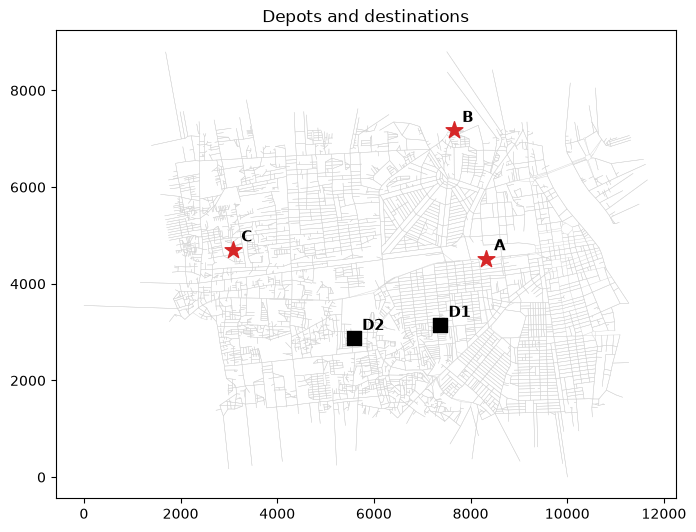

In [32]:

def plot_scenario(G, labels, van_routes=None, title="Depots and destinations"):
    """
    labels     : {"D1": node, "D2": node, "A": node, ...}
    van_routes : optional {"Van 1": [node, node, ...], "Van 2": [...]}  (full road paths)
    """
    fig, ax = plt.subplots(figsize=(8, 8))

    # road network (drawn as one collection, much faster than one plot per edge)
    segments = [(G.nodes[u]["pos"], G.nodes[v]["pos"]) for u, v in G.edges]
    ax.add_collection(LineCollection(segments, colors="lightgray", linewidths=0.3, zorder=1))

    # optional routes
    if van_routes:
        for (van_name, path), colour in zip(van_routes.items(), ["tab:blue", "tab:orange"]):
            xs, ys = zip(*(G.nodes[n]["pos"] for n in path))
            ax.plot(xs, ys, lw=2, color=colour, zorder=2, label=van_name)

    # depots and destinations
    for name, node in labels.items():
        x, y = G.nodes[node]["pos"]
        is_depot = name.startswith("D")
        ax.scatter(x, y, marker="s" if is_depot else "*",
                   s=100 if is_depot else 160,
                   c="black" if is_depot else "tab:red", zorder=3)
        ax.annotate(name, (x, y), xytext=(6, 6), textcoords="offset points",
                    fontsize=11, fontweight="bold")

    ax.autoscale()
    ax.set_aspect("equal")
    ax.set_title(title)
    if van_routes:
        ax.legend(loc="best")
    plt.show()

plot_scenario(G, labels)

In [33]:

def van_legs(G, labels, van1_stops, van2_stops):
    """One entry per stop-to-stop leg: depot -> stop -> ... -> back to its own depot."""
    legs = []
    for van, depot, stops in [("Van 1", "D1", van1_stops), ("Van 2", "D2", van2_stops)]:
        seq = [depot] + list(stops) + [depot]
        for a, b in zip(seq, seq[1:]):
            if a == b:                      # idle van: nothing to draw
                continue
            path = nx.shortest_path(G, labels[a], labels[b], weight="weight")
            legs.append({"van": van, "from": a, "to": b, "path": path})
    return legs

In [34]:


def plot_plan(G, labels, legs, d=None, title="Optimal plan from QUBO"):
    fig, ax = plt.subplots(figsize=(9, 9))

    segments = [(G.nodes[u]["pos"], G.nodes[v]["pos"]) for u, v in G.edges]
    ax.add_collection(LineCollection(segments, colors="lightgray", linewidths=0.3, zorder=1))

    palette = plt.get_cmap("tab10").colors
    legend_items = []
    n_legs = len(legs)
    for k, leg in enumerate(legs):
        colour = palette[k % len(palette)]
        xs, ys = zip(*(G.nodes[n]["pos"] for n in leg["path"]))
        # earlier legs thicker, later legs thinner on top, so shared roads show both colours
        lw = 2 + 3 * (n_legs - 1 - k) / max(n_legs - 1, 1)
        ax.plot(xs, ys, lw=lw, color=colour, zorder=2 + k * 0.01, solid_capstyle="round")

        # direction arrow near the middle of the leg
        mid = len(leg["path"]) // 2
        if mid > 0:
            (x0, y0) = G.nodes[leg["path"][mid - 1]]["pos"]
            (x1, y1) = G.nodes[leg["path"][mid]]["pos"]
            arrow = ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=4,
                    arrowprops=dict(arrowstyle="-|>", color=colour, lw=1, mutation_scale=12))

            arrow.arrow_patch.set_path_effects([
                pe.Stroke(linewidth=2, foreground="black"),
                pe.Normal()
            ])

        text = f'{leg["van"]}: {leg["from"]} \u2192 {leg["to"]}'
        if d is not None:
            text += f' ({d[(leg["from"], leg["to"])]:.0f} s)'
        legend_items.append(Line2D([0], [0], color=colour, lw=3, label=text))

    for name, node in labels.items():
        x, y = G.nodes[node]["pos"]
        is_depot = name.startswith("D")
        ax.scatter(x, y, marker="s" if is_depot else "*", s=110 if is_depot else 170,
                   c="black" if is_depot else "tab:red", zorder=5,
                   edgecolors="white", linewidths=0.8)
        ax.annotate(name, (x, y), xytext=(7, 7), textcoords="offset points",
                    fontsize=11, fontweight="bold", zorder=6)

    legend_items += [
        Line2D([0], [0], marker="s", color="w", markerfacecolor="black", markersize=9, label="Depot"),
        Line2D([0], [0], marker="*", color="w", markerfacecolor="tab:red", markersize=13, label="Destination"),
    ]
    ax.legend(handles=legend_items, loc="upper left", fontsize=8, framealpha=0.95)
    ax.autoscale(); ax.set_aspect("equal"); ax.set_title(title)
    plt.show()

Tour: ['D1', 'A', 'B', 'D2', 'C']
Van 1: ['A', 'B'] | Van 2: ['C']
Optimal total travel time: 847.50 s


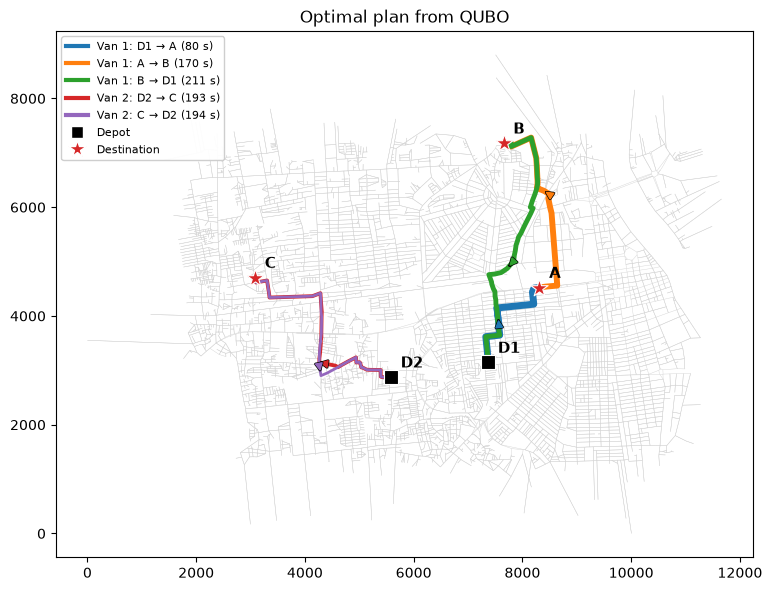

In [35]:
bits, energy = solve_exact(Q, variables)
tour, van1_stops, van2_stops = decode(bits, variables, dest_labels)
print("Tour:", tour)
print("Van 1:", van1_stops, "| Van 2:", van2_stops)
print(f"Optimal total travel time: {(energy + offset) * mc:.2f} s")

legs = van_legs(G, labels, van1_stops, van2_stops)
plot_plan(G, labels, legs, d=d)

## 6. Inspect QUBO Matrix & Build Cost Hamiltonian (for QAOA)

In [36]:
# Create an empty 16 x 16 matrix
n = len(variables)
matrix = np.zeros((n, n))

# Map each QUBO coefficient to its matrix position
for (v1, v2), coefficient in Q.items():
    i = variables.index(v1)
    j = variables.index(v2)

    matrix[i, j] = coefficient

# Use variable names as row and column labels
labels = [f"{node}_{position}" for node, position in variables]

qubo_matrix = pd.DataFrame(
    matrix,
    index=labels,
    columns=labels
)

print(qubo_matrix.round(2))


      D2_1  D2_2  D2_3  D2_4   A_1   A_2   A_3   A_4   B_1   B_2   B_3   B_4  \
D2_1  -2.0   2.0   2.0   2.0  2.00  0.48  0.00  0.00  2.00  0.79  0.00  0.00   
D2_2   0.0  -2.0   2.0   2.0  0.28  2.00  0.48  0.00  0.53  2.00  0.79  0.00   
D2_3   0.0   0.0  -2.0   2.0  0.00  0.28  2.00  0.48  0.00  0.53  2.00  0.79   
D2_4   0.0   0.0   0.0  -2.0  0.00  0.00  0.28  2.00  0.00  0.00  0.53  2.00   
A_1    0.0   0.0   0.0   0.0 -1.80  2.00  2.00  2.00  2.00  0.43  0.00  0.00   
A_2    0.0   0.0   0.0   0.0  0.00 -2.00  2.00  2.00  0.46  2.00  0.43  0.00   
A_3    0.0   0.0   0.0   0.0  0.00  0.00 -2.00  2.00  0.00  0.46  2.00  0.43   
A_4    0.0   0.0   0.0   0.0  0.00  0.00  0.00 -1.44  0.00  0.00  0.46  2.00   
B_1    0.0   0.0   0.0   0.0  0.00  0.00  0.00  0.00 -1.50  2.00  2.00  2.00   
B_2    0.0   0.0   0.0   0.0  0.00  0.00  0.00  0.00  0.00 -2.00  2.00  2.00   
B_3    0.0   0.0   0.0   0.0  0.00  0.00  0.00  0.00  0.00  0.00 -2.00  2.00   
B_4    0.0   0.0   0.0   0.0  0.00  0.00

### Ising Hamiltonian & Cost Hamiltonian

In [37]:
# Convert the QUBO from Section 4 to Ising and Qiskit Cost Hamiltonian
h, J, ising_offset = qubo_to_ising(Q, variables, offset)
cost_hamiltonian = ising_to_cost_hamiltonian(h, J, ising_offset, variables)

print("========== ISING MODEL ==========")

print("\n--- Individual spin coefficients (h) ---")
for variable, coefficient in h.items():
    print(f"{str(variable):20} {coefficient:12.4f}")

print("\n--- Interaction coefficients (J) ---")
for (v1, v2), coefficient in J.items():
    print(f"{str(v1):12} <-> {str(v2):12} {coefficient:12.4f}")

print(f"\nIsing offset: {ising_offset:.4f}")

print("\n========== COST HAMILTONIAN ==========")

for pauli, coefficient in zip(
    cost_hamiltonian.paulis,
    cost_hamiltonian.coeffs
):
    print(f"{str(pauli):20} {coefficient.real:12.4f}")

========== ISING MODEL ==========

--- Individual spin coefficients (h) ---
('D2', 1)                 -2.4396
('D2', 2)                 -2.8376
('D2', 3)                 -2.8376
('D2', 4)                 -2.3980
('A', 1)                  -2.4917
('A', 2)                  -2.8263
('A', 3)                  -2.8263
('A', 4)                  -2.7136
('B', 1)                  -2.7495
('B', 2)                  -3.0160
('B', 3)                  -3.0160
('B', 4)                  -2.9206
('C', 1)                  -2.9868
('C', 2)                  -3.1942
('C', 3)                  -3.1942
('C', 4)                  -2.8285

--- Interaction coefficients (J) ---
('D2', 1)    <-> ('D2', 2)          0.5000
('D2', 1)    <-> ('D2', 3)          0.5000
('D2', 1)    <-> ('D2', 4)          0.5000
('D2', 2)    <-> ('D2', 3)          0.5000
('D2', 2)    <-> ('D2', 4)          0.5000
('D2', 3)    <-> ('D2', 4)          0.5000
('A', 1)     <-> ('A', 2)           0.5000
('A', 1)     <-> ('A', 3)           0.500

## 7. QAOA Setup & Reusable Helper Functions

All QAOA logic (ansatz construction, noise model, primitives, optimizer loop, decoding, and plotting) is organized into reusable functions so Ideal, Noisy, Error-Suppressed, and Error-Mitigated runs share the exact same pipeline.

In [38]:
# Selected Classical Optimizers (Diverse)
C_OPTIMIZER = {
    "COBYLA": {
        "runner": "scipy",
        "scipy_method": "COBYLA",
        "family": "Trust-region / simplex derivative-free",
        "desc": "Good baseline for smooth or moderate-dimensional parameter spaces; sensitive to step size and shot noise.",
    },
    "POWELL": {
        "runner": "scipy",
        "scipy_method": "POWELL",
        "family": "Direction-set / coordinate-style derivative-free",
        "desc": "Often more resilient on rugged or noisy objective landscapes than simplex methods under moderate evaluation budgets.",
    },
    "L-BFGS-B": {
        "runner": "scipy",
        "scipy_method": "L-BFGS-B",
        "family": "Quasi-Newton / gradient-based",
        "desc": "Fast and accurate on smooth, low-noise landscapes, though sensitive to noisy finite-difference estimates.",
    },
    "SPSA": {
        "runner": "spsa",
        "scipy_method": None,
        "family": "Stochastic perturbation",
        "desc": "Well-suited for noisy/shot-based runs and fake devices, estimating gradients with only 2 evaluations per step.",
    },
}

In [39]:
def build_noise_model(p_1q: float = 0.001, p_2q: float = 0.01, p_readout: float = 0.02) -> NoiseModel:
    """Create a configurable Aer NoiseModel (1q/2q depolarizing + symmetric readout error)."""
    noise_model = NoiseModel()
    if p_1q > 0:
        noise_model.add_all_qubit_quantum_error(
            depolarizing_error(p_1q, 1), ["rx", "ry", "rz", "h", "sx", "x"]
        )
    if p_2q > 0:
        noise_model.add_all_qubit_quantum_error(
            depolarizing_error(p_2q, 2), ["cx", "cz", "rzz"]
        )
    if p_readout > 0:
        noise_model.add_all_qubit_readout_error(
            ReadoutError([[1.0 - p_readout, p_readout], [p_readout, 1.0 - p_readout]])
        )
    return noise_model


def make_qaoa_primitives(
    mode: str = "ideal",
    noise_model: NoiseModel | None = None,
    shots: int = 1024,
    seed: int = 42,
    device: str = "GPU",
):
    """Return (estimator, sampler, backend) for 'ideal' or 'noisy' QAOA simulation.

    Uses Qiskit Aer on GPU by default (with automatic fallback to CPU if unavailable).
    """
    available = AerSimulator().available_devices()
    if device == "GPU" and "GPU" not in available:
        print("Warning: GPU not available in AerSimulator; falling back to CPU.")
        device = "CPU"

    backend_options = {"method": "statevector", "device": device}
    if device == "GPU":
        backend_options["cuStateVec_enable"] = True

    if mode == "ideal":
        backend = AerSimulator(**backend_options)
        estimator = AerEstimator(options={"backend_options": backend_options})
        sampler = AerSampler(
            default_shots=shots,
            seed=seed,
            options={"backend_options": backend_options},
        )
        return estimator, sampler, backend

    if mode == "noisy":
        if noise_model is None:
            noise_model = build_noise_model()
        noisy_backend_options = {**backend_options, "noise_model": noise_model}
        if device == "GPU":
            noisy_backend_options.update(
                {
                    "precision": "single",
                    "batched_shots_gpu": True,
                    "max_shot_size": 256,
                }
            )
        backend = AerSimulator(**noisy_backend_options)
        estimator = AerEstimator(
            options={
                "backend_options": noisy_backend_options,
                "run_options": {"shots": shots, "seed_simulator": seed},
            }
        )
        sampler = AerSampler(
            default_shots=shots,
            seed=seed,
            options={"backend_options": noisy_backend_options},
        )
        return estimator, sampler, backend

    raise ValueError(f"Unsupported mode: {mode!r} (use 'ideal' or 'noisy')")


def build_qaoa_ansatz(
    cost_hamiltonian,
    reps: int = 2,
    backend=None,
    optimization_level: int = 1,
    circuit_transform=None,
):
    """Build a QAOA ansatz, optionally transpiled for a backend and/or transformed (e.g. error suppression)."""
    ansatz = qaoa_ansatz(cost_operator=cost_hamiltonian, reps=reps, flatten=True)
    if backend is not None:
        ansatz = transpile(ansatz, backend=backend, optimization_level=optimization_level)
    if circuit_transform is not None:
        ansatz = circuit_transform(ansatz)
    return ansatz

In [40]:
def run_optimizer(
    opt_key: str, cfg: dict, objective_fn, init_params: np.ndarray, maxiter: int = 200
):
    if cfg["runner"] == "scipy":
        return minimize(
            objective_fn,
            init_params,
            method=cfg["scipy_method"],
            options={"maxiter": maxiter},
        )

    if cfg["runner"] == "spsa":
        spsa = SPSA(maxiter=maxiter)
        spsa_res = spsa.minimize(fun=objective_fn, x0=init_params)
        return SimpleNamespace(
            x=spsa_res.x,
            fun=float(spsa_res.fun),
            nfev=spsa_res.nfev,
            success=True,
        )

    raise ValueError(f"Unsupported runner: {cfg['runner']}")


def run_qaoa_single(
    opt_key: str,
    cfg: dict,
    ansatz,
    cost_hamiltonian,
    estimator,
    sampler,
    variables: list,
    d: dict,
    mc: float,
    init_params: np.ndarray | None = None,
    maxiter: int = 200,
    shots: int = 4096,
    postprocess_counts=None,
) -> dict:
    """Run QAOA with one classical optimizer, sample bitstrings, and decode feasible tours.

    Pass a custom `estimator`/`sampler` or `postprocess_counts` hook to plug in error mitigation.
    """
    if init_params is None:
        init_params = np.full(ansatz.num_parameters, 0.1)

    history = []

    def objective(params: np.ndarray) -> float:
        ev = float(estimator.run([(ansatz, cost_hamiltonian, params)]).result()[0].data.evs)
        history.append(ev)
        return ev

    t0 = time.perf_counter()
    result = run_optimizer(opt_key, cfg, objective, init_params, maxiter=maxiter)
    elapsed = time.perf_counter() - t0

    bound_circuit = ansatz.assign_parameters(result.x)
    bound_circuit.measure_all()
    counts = sampler.run([(bound_circuit,)], shots=shots).result()[0].data.meas.get_counts()
    if postprocess_counts is not None:
        counts = postprocess_counts(counts)

    top_candidates = sorted(counts.items(), key=lambda item: item[1], reverse=True)[:5]

    # Decode feasible tours from sampled bitstrings
    feasible_shots = 0
    best_tour, best_time = None, float("inf")
    for bitstring, cnt in counts.items():
        tour = decode_tour(bitstring_to_assignment(bitstring, variables))
        if tour is not None:
            feasible_shots += cnt
            t_s = total_distance(d, tour)
            if t_s < best_time:
                best_time, best_tour = t_s, tour

    # Note: cost_hamiltonian already includes ising_offset, so result.fun is the true normalised <H_C>
    final_energy = float(result.fun)
    return {
        "optimizer": opt_key,
        "family": cfg["family"],
        "desc": cfg["desc"],
        "result": result,
        "energy": final_energy,
        "travel_time_s": final_energy * mc,
        "history": history,
        "counts": counts,
        "top_candidates": top_candidates,
        "feasible_prob": (feasible_shots / shots) * 100.0,
        "best_feasible_tour": best_tour,
        "best_feasible_time_s": best_time if best_tour is not None else None,
        "elapsed_s": elapsed,
    }


def run_qaoa_suite(
    optimizers: dict,
    ansatz,
    cost_hamiltonian,
    estimator,
    sampler,
    variables: list,
    d: dict,
    mc: float,
    init_params: np.ndarray | None = None,
    maxiter: int = 200,
    shots: int = 4096,
    postprocess_counts=None,
) -> dict:
    """Run QAOA across all configured optimizers and print a summary table."""
    results = {}
    print(f"{'Optimizer':<10} {'<H_C>':>9} {'Feas %':>8} {'Best Tour (s)':>15} {'nfev':>6} {'Time (s)':>9}")
    print("-" * 62)
    for opt_key, cfg in optimizers.items():
        res = run_qaoa_single(
            opt_key, cfg, ansatz, cost_hamiltonian, estimator, sampler,
            variables, d, mc, init_params=init_params, maxiter=maxiter,
            shots=shots, postprocess_counts=postprocess_counts,
        )
        results[opt_key] = res
        best_str = f"{res['best_feasible_time_s']:.1f}" if res["best_feasible_time_s"] is not None else "none"
        print(
            f"{opt_key:<10} {res['energy']:>9.4f} {res['feasible_prob']:>7.2f}% "
            f"{best_str:>15} {res['result'].nfev:>6} {res['elapsed_s']:>9.1f}"
        )
    return results

In [41]:
def plot_qaoa_comparison(results: dict, shots: int, title_prefix: str = "QAOA", optimal_energy: float | None = None):
    """Plot optimizer comparison (energy, top bitstring %, nfev) and top-5 bitstring distributions."""
    opt_names = list(results.keys())
    energies = [results[k]["energy"] for k in opt_names]
    nfevs = [results[k]["result"].nfev for k in opt_names]
    top_probs = [
        (results[k]["top_candidates"][0][1] / shots) * 100.0 if results[k]["top_candidates"] else 0.0
        for k in opt_names
    ]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    fig.suptitle(f"{title_prefix} — Optimizer Comparison", fontsize=13, fontweight="bold")

    axes[0].bar(opt_names, energies)
    if optimal_energy is not None:
        axes[0].axhline(optimal_energy, color="tab:red", linestyle="--", label=f"Optimum ({optimal_energy:.2f})")
        axes[0].legend()
    axes[0].set_title("Final Objective Value")
    axes[0].set_ylabel("Normalised Energy <H_C>")
    axes[0].tick_params(axis="x", rotation=30)

    axes[1].bar(opt_names, top_probs)
    axes[1].set_title("Top Bitstring Frequency (%)")
    axes[1].set_ylabel("Share of Shots (%)")
    axes[1].tick_params(axis="x", rotation=30)

    axes[2].bar(opt_names, nfevs)
    axes[2].set_title("Function Evaluations (nfev)")
    axes[2].set_ylabel("Evaluations")
    axes[2].tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.show()

    # Top-5 bitstring distribution per optimizer
    n_opts = len(opt_names)
    cols = min(2, n_opts)
    rows = (n_opts + cols - 1) // cols
    fig2, axes2 = plt.subplots(rows, cols, figsize=(7 * cols, 4 * rows), squeeze=False)
    fig2.suptitle(f"{title_prefix} — Top-5 Sampled Bitstrings", fontsize=13, fontweight="bold")

    for idx, opt_key in enumerate(opt_names):
        r, c = divmod(idx, cols)
        ax = axes2[r][c]
        top5 = results[opt_key]["top_candidates"]
        bit_labels = [b for b, _ in top5]
        freqs = [cnt for _, cnt in top5]
        ax.barh(bit_labels[::-1], freqs[::-1])
        ax.set_title(f"{opt_key} (feasible: {results[opt_key]['feasible_prob']:.1f}%)")
        ax.set_xlabel(f"Counts (out of {shots} shots)")

    for idx in range(n_opts, rows * cols):
        r, c = divmod(idx, cols)
        axes2[r][c].axis("off")

    plt.tight_layout()
    plt.show()


def plot_qaoa_convergence(results: dict, title: str = "QAOA Convergence", optimal_energy: float | None = None):
    """Plot energy vs. function evaluation for each optimizer."""
    fig, ax = plt.subplots(figsize=(10, 4))
    for opt_key, res in results.items():
        ax.plot(res["history"], label=opt_key)
    if optimal_energy is not None:
        ax.axhline(optimal_energy, color="tab:red", linestyle="--", label=f"Optimum ({optimal_energy:.2f})")
    ax.set_title(title)
    ax.set_xlabel("Objective Evaluation")
    ax.set_ylabel("Normalised Energy <H_C>")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def compare_qaoa_runs(run_map: dict, optimal_energy: float | None = None):
    """Side-by-side comparison across simulation modes (e.g. Ideal, Noisy, Mitigated)."""
    mode_names = list(run_map.keys())
    opt_names = list(dict.fromkeys(k for res in run_map.values() for k in res.keys()))
    x = np.arange(len(opt_names))
    width = 0.8 / len(mode_names)

    fig, ax = plt.subplots(figsize=(11, 4.5))
    for i, mode in enumerate(mode_names):
        vals = [run_map[mode][k]["energy"] if k in run_map[mode] else np.nan for k in opt_names]
        ax.bar(x + (i - (len(mode_names) - 1) / 2) * width, vals, width, label=mode)
    if optimal_energy is not None:
        ax.axhline(optimal_energy, color="tab:red", linestyle="--", label=f"Optimum ({optimal_energy:.2f})")
    ax.set_xticks(x)
    ax.set_xticklabels(opt_names)
    ax.set_ylabel("Normalised Energy <H_C>")
    ax.set_title("QAOA Final Energy Across Simulation Modes")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

## 8. QAOA Ideal Simulation (Depth Sweep $p = 1, 2, 3$)


==================== Ideal QAOA (p = 1) ====================
Optimizer      <H_C>   Feas %   Best Tour (s)   nfev  Time (s)
--------------------------------------------------------------
COBYLA       23.4550    0.00%            none    150       6.9
POWELL        5.5219    1.44%           883.5    114       5.1
L-BFGS-B      5.5219    1.44%           883.5     51       2.3
SPSA         18.8526    0.12%           847.5    300      15.1

==================== Ideal QAOA (p = 2) ====================
Optimizer      <H_C>   Feas %   Best Tour (s)   nfev  Time (s)
--------------------------------------------------------------
COBYLA        8.0834    0.66%           883.5    150       7.0
POWELL        4.8713    1.93%           847.5    223       9.8
L-BFGS-B      4.8713    1.61%           847.5    175       8.8
SPSA         15.5800    0.15%           939.5    300      15.6

==================== Ideal QAOA (p = 3) ====================
Optimizer      <H_C>   Feas %   Best Tour (s)   nfev  Time

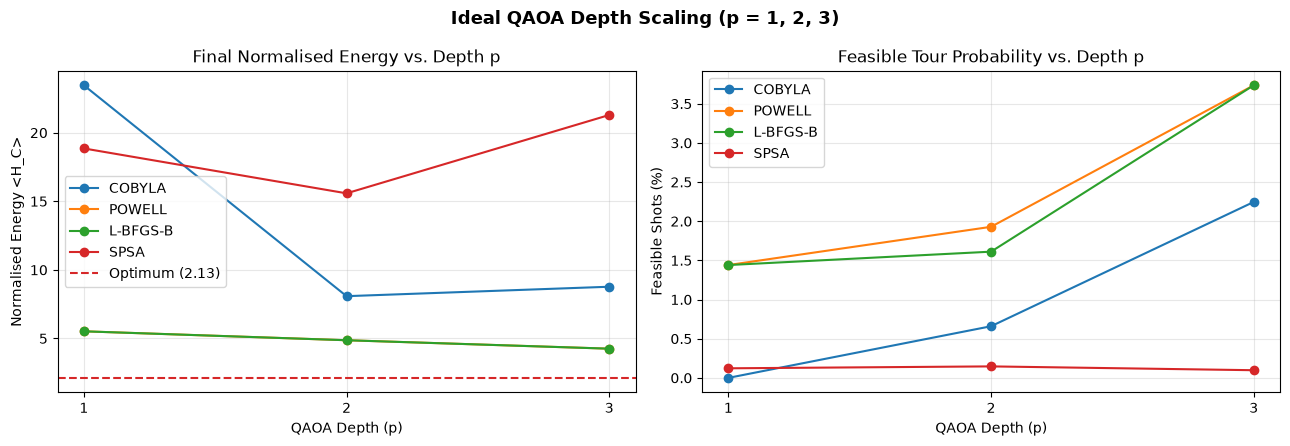

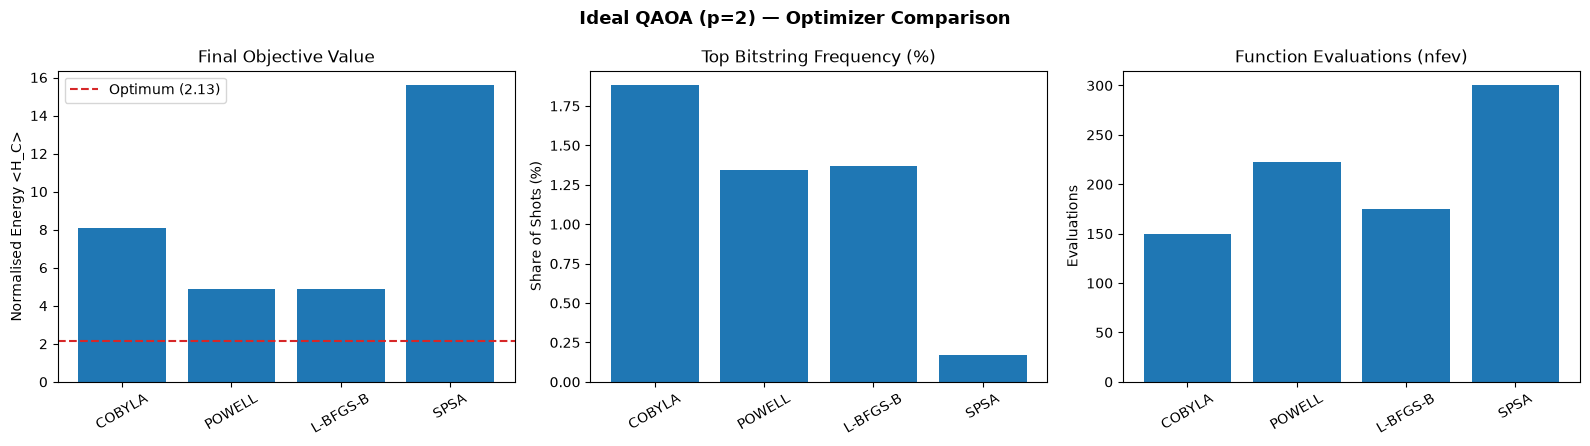

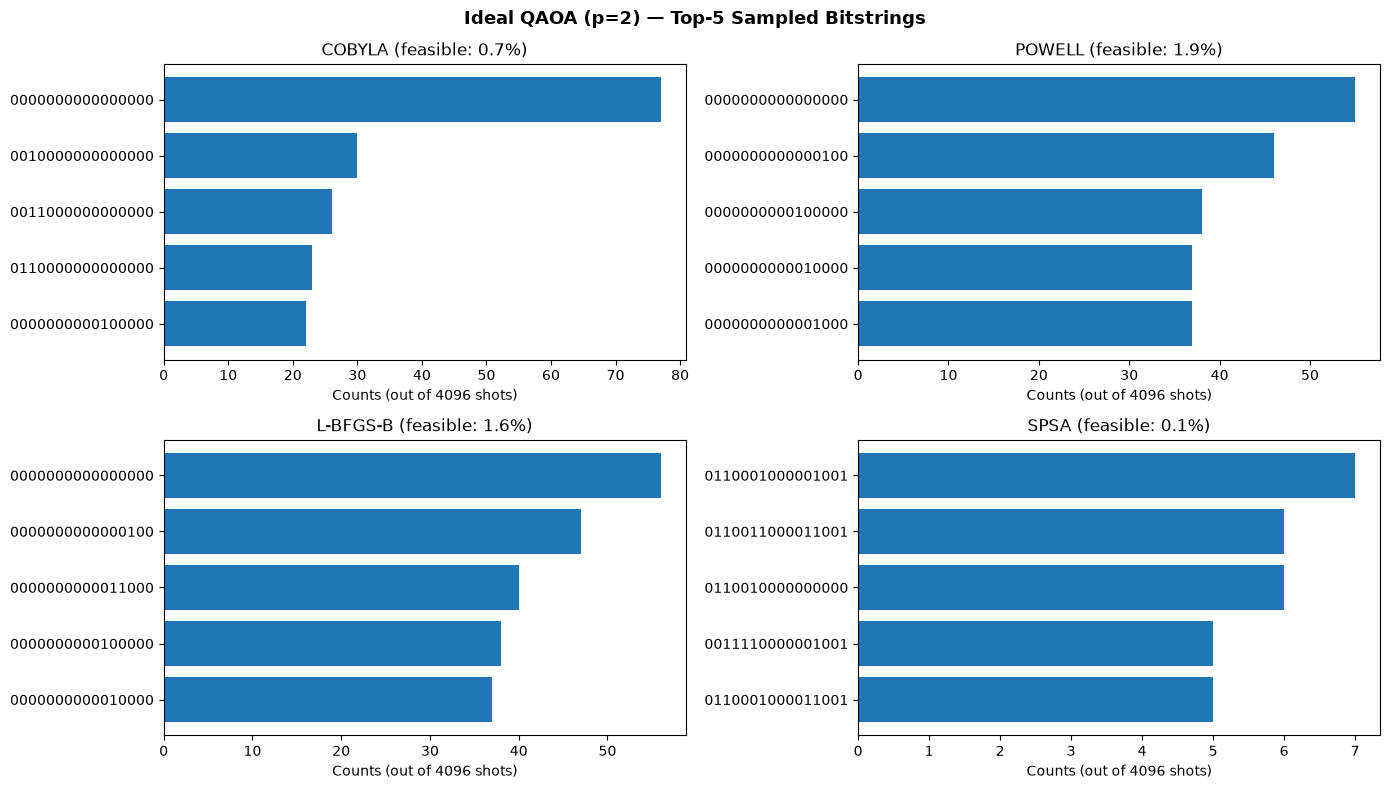

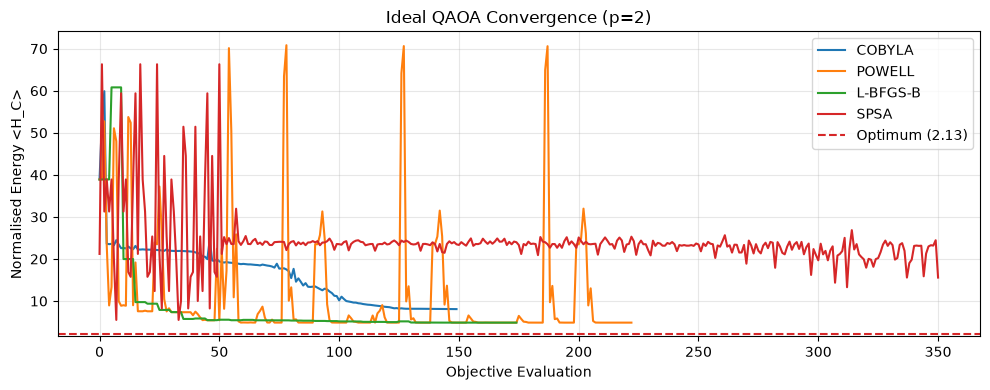

In [42]:
IDEAL_REPS_LIST = [1, 2, 3]          # sweep QAOA depth p = 1..3 in fast Ideal GPU mode
QAOA_REPS = 2                        # fixed depth carried into Noisy (Sec. 9) & DD -> GZNE (Sec. 11)
SAMPLE_SHOTS = 4096
opt_energy = float(energy + offset)  # brute-force normalised optimum from Section 5 (reference only)

ideal_estimator, ideal_sampler, _ = make_qaoa_primitives(mode="ideal", shots=SAMPLE_SHOTS, seed=42)

ideal_sweep_results = {}
ideal_sweep_ansatz = {}
for p in IDEAL_REPS_LIST:
    print(f"\n==================== Ideal QAOA (p = {p}) ====================")
    ansatz_p = build_qaoa_ansatz(cost_hamiltonian, reps=p)
    ideal_sweep_ansatz[p] = ansatz_p
    ideal_sweep_results[p] = run_qaoa_suite(
        C_OPTIMIZER,
        ansatz=ansatz_p,
        cost_hamiltonian=cost_hamiltonian,
        estimator=ideal_estimator,
        sampler=ideal_sampler,
        variables=variables,
        d=d,
        mc=mc,
        maxiter=150,
        shots=SAMPLE_SHOTS,
    )

# Depth-scaling summary plot across p = 1, 2, 3
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
fig.suptitle("Ideal QAOA Depth Scaling (p = 1, 2, 3)", fontsize=13, fontweight="bold")
for opt_key in C_OPTIMIZER:
    axes[0].plot(
        IDEAL_REPS_LIST,
        [ideal_sweep_results[p][opt_key]["energy"] for p in IDEAL_REPS_LIST],
        marker="o",
        label=opt_key,
    )
    axes[1].plot(
        IDEAL_REPS_LIST,
        [ideal_sweep_results[p][opt_key]["feasible_prob"] for p in IDEAL_REPS_LIST],
        marker="o",
        label=opt_key,
    )
axes[0].axhline(opt_energy, color="tab:red", linestyle="--", label=f"Optimum ({opt_energy:.2f})")
axes[0].set_title("Final Normalised Energy vs. Depth p")
axes[0].set_xlabel("QAOA Depth (p)")
axes[0].set_ylabel("Normalised Energy <H_C>")
axes[0].set_xticks(IDEAL_REPS_LIST)
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Feasible Tour Probability vs. Depth p")
axes[1].set_xlabel("QAOA Depth (p)")
axes[1].set_ylabel("Feasible Shots (%)")
axes[1].set_xticks(IDEAL_REPS_LIST)
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Select fixed QAOA_REPS (p = 2) for detailed plots and downstream Noisy / DD -> GZNE sections
ideal_ansatz = ideal_sweep_ansatz[QAOA_REPS]
ideal_results = ideal_sweep_results[QAOA_REPS]

plot_qaoa_comparison(ideal_results, shots=SAMPLE_SHOTS, title_prefix=f"Ideal QAOA (p={QAOA_REPS})", optimal_energy=opt_energy)
plot_qaoa_convergence(ideal_results, title=f"Ideal QAOA Convergence (p={QAOA_REPS})", optimal_energy=opt_energy)

## 9. QAOA Noisy Simulation

Runs the exact same QAOA pipeline with a depolarizing + readout `NoiseModel`.

Optimizer      <H_C>   Feas %   Best Tour (s)   nfev  Time (s)
--------------------------------------------------------------
COBYLA       22.7543    0.02%           958.5     25      39.8
SPSA         21.4928    0.12%           847.5     50     163.2


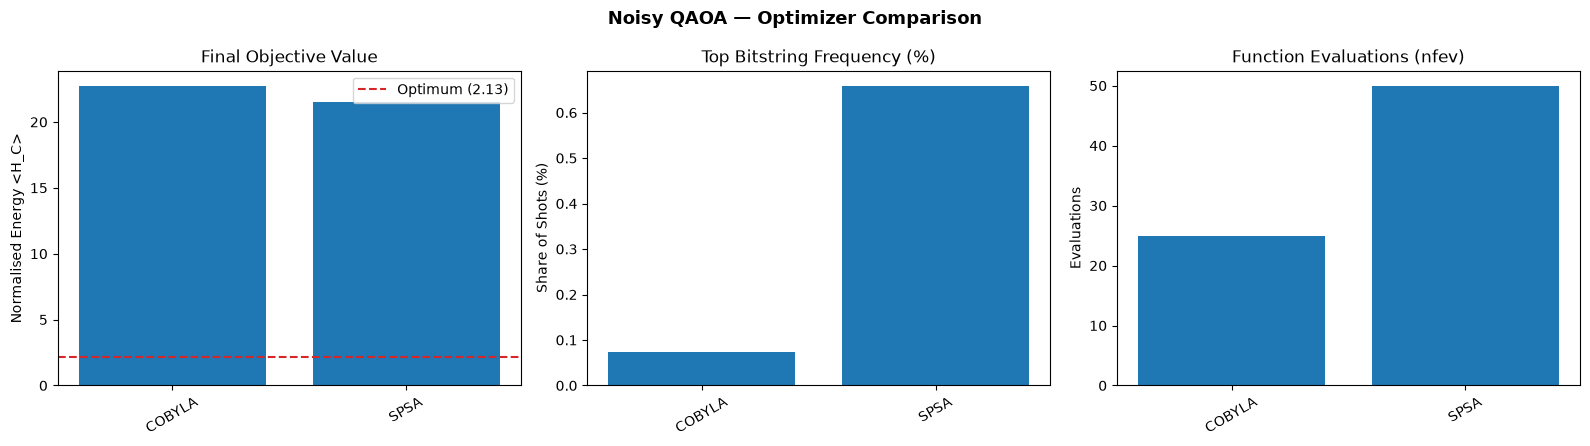

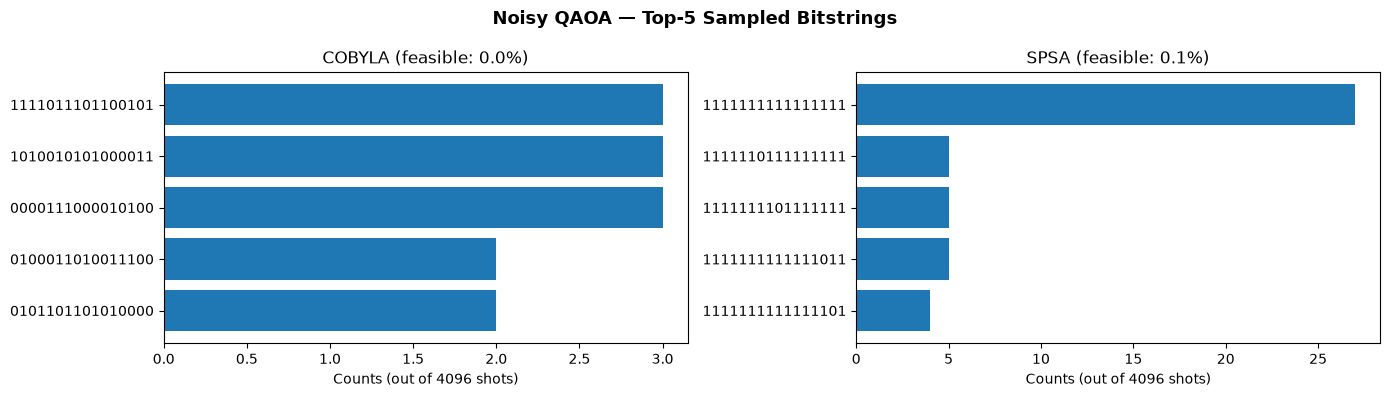

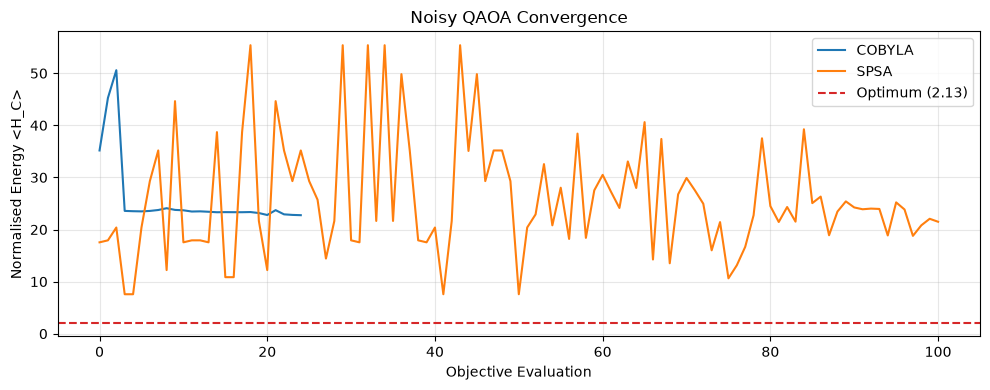

In [44]:
NOISY_OPT_SHOTS = 256   # shots per objective evaluation during noisy optimization (~1.6 s/eval on GPU)
NOISY_MAXITER = 25      # keep runtime to ~3-5 min total on 16-qubit noisy GPU simulation
NOISY_OPTIMIZERS = {k: C_OPTIMIZER[k] for k in ("COBYLA", "SPSA")}  # swap to C_OPTIMIZER to run all 4

noise_model = build_noise_model(p_1q=0.001, p_2q=0.01, p_readout=0.02)
noisy_estimator, noisy_sampler, noisy_backend = make_qaoa_primitives(
    mode="noisy", noise_model=noise_model, shots=NOISY_OPT_SHOTS, seed=42
)
noisy_ansatz = build_qaoa_ansatz(cost_hamiltonian, reps=QAOA_REPS, backend=noisy_backend)

noisy_results = run_qaoa_suite(
    NOISY_OPTIMIZERS,
    ansatz=noisy_ansatz,
    cost_hamiltonian=cost_hamiltonian,
    estimator=noisy_estimator,
    sampler=noisy_sampler,
    variables=variables,
    d=d,
    mc=mc,
    maxiter=NOISY_MAXITER,
    shots=SAMPLE_SHOTS,
)

plot_qaoa_comparison(noisy_results, shots=SAMPLE_SHOTS, title_prefix="Noisy QAOA", optimal_energy=opt_energy)
plot_qaoa_convergence(noisy_results, title="Noisy QAOA Convergence", optimal_energy=opt_energy)

## 10. Ideal vs Noisy Comparison

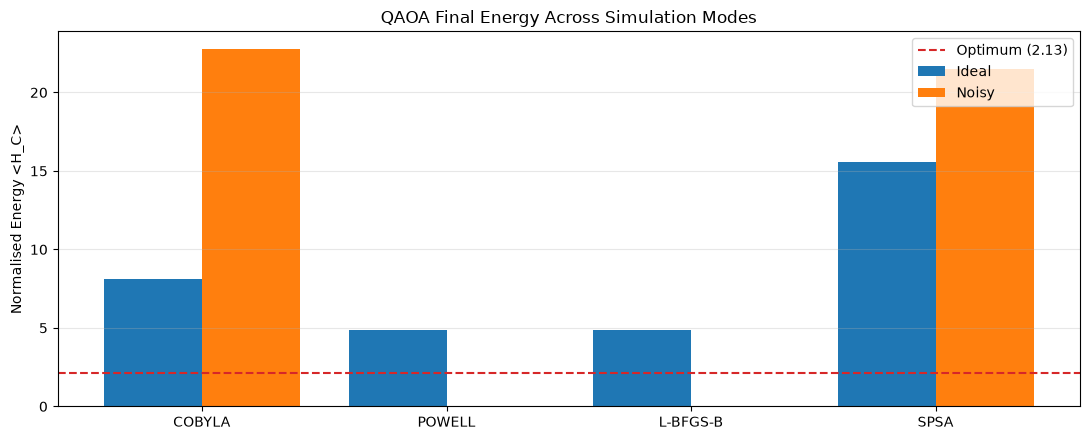

In [45]:
compare_qaoa_runs(
    {"Ideal": ideal_results, "Noisy": noisy_results},
    optimal_energy=opt_energy,
)

## 11. Gate-level (Local) ZNE on Custom Depolarizing `NoiseModel`

Demonstrates **Gate-level (Local) Zero-Noise Extrapolation (ZNE)** in the low-depth, all-to-all regime (no SWAP-routing blowup or $T_1$ collapse) using the best converged Ideal QAOA circuit from Section 8:
- Transpiles to `['rx', 'ry', 'rz', 'h', 'cx']` (336 `cx` gates at $p = 2$; `p_2q = 0.005` per `cx` $\approx$ 1% per `rzz` pair, matching Section 9).
- Applies `qiskit_mitigation.zne.GateFoldingPass` at scale factors $\lambda \in \{1.0, 1.5, 2.0\}$ (folding `cx` gates: 336 → 504 → 672) and extrapolates to $\lambda = 0$ via **Linear** and **Richardson (quadratic)** fits.

Evaluating L-BFGS-B (Ideal QAOA <H_C> = 4.8713) on custom depolarizing NoiseModel...
Base circuit: depth=116, ops={'cx': 336, 'rz': 200, 'rx': 32, 'h': 16}
  lambda=1.0 (cx=336)  <H_C> =   6.7956  (9.3 s)
  lambda=1.5 (cx=504)  <H_C> =   7.8127  (10.9 s)
  lambda=2.0 (cx=672)  <H_C> =   8.8596  (12.6 s)

Stage                        <H_C>  |Err vs Ideal|
--------------------------------------------------
Ideal QAOA (noiseless)      4.8713          0.0000
Noisy (lambda=1.0)          6.7956          1.9244
+ GZNE (Linear)             4.7267          0.1445
+ GZNE (Richardson)         4.8509          0.0204


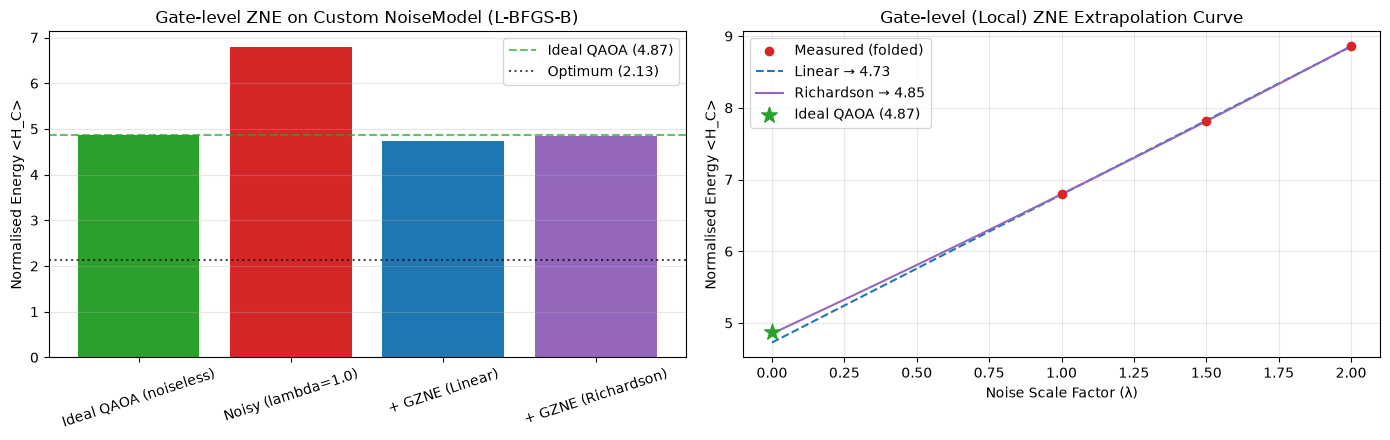

In [46]:
from qiskit_mitigation.zne import GateFoldingPass

CUSTOM_ZNE_SHOTS = 1024          # high shot count for clean extrapolation (~30 s total on GPU)
ZNE_SCALE_FACTORS = [1.0, 1.5, 2.0]

# 1. Pick the best converged Ideal circuit from Section 8
best_opt = min(ideal_results, key=lambda k: ideal_results[k]["energy"])
best_params = ideal_results[best_opt]["result"].x
ev_ideal = ideal_results[best_opt]["energy"]

# 2. Transpile to {rx, ry, rz, h, cx} so GateFoldingPass folds every 2-qubit cx gate cleanly
bound_ideal = ideal_ansatz.assign_parameters(best_params)
cx_circ = transpile(bound_ideal, basis_gates=["rx", "ry", "rz", "h", "cx"], optimization_level=1)
print(f"Evaluating {best_opt} (Ideal QAOA <H_C> = {ev_ideal:.4f}) on custom depolarizing NoiseModel...")
print(f"Base circuit: depth={cx_circ.depth()}, ops={dict(cx_circ.count_ops())}")

# 3. Custom depolarizing + readout noise (p_2q=0.005/cx ≈ 1% per rzz pair, matching Section 9)
zne_noise_model = build_noise_model(p_1q=0.001, p_2q=0.005, p_readout=0.02)
zne_estimator, _, _ = make_qaoa_primitives(
    mode="noisy", noise_model=zne_noise_model, shots=CUSTOM_ZNE_SHOTS, seed=42
)

custom_zne_evs = []
for sf in ZNE_SCALE_FACTORS:
    circ_sf = cx_circ if sf == 1.0 else GateFoldingPass(noise_factor=sf, seed=42)(cx_circ)
    t0 = time.perf_counter()
    ev = float(zne_estimator.run([(circ_sf, cost_hamiltonian)]).result()[0].data.evs)
    custom_zne_evs.append(ev)
    print(f"  lambda={sf:.1f} (cx={circ_sf.count_ops().get('cx', 0):3d})  <H_C> = {ev:8.4f}  ({time.perf_counter() - t0:.1f} s)")

ev_custom_noisy = custom_zne_evs[0]
c_lin_coeffs = np.polyfit(ZNE_SCALE_FACTORS, custom_zne_evs, deg=1)
ev_custom_lin = float(np.polyval(c_lin_coeffs, 0.0))
c_rich_coeffs = np.polyfit(ZNE_SCALE_FACTORS, custom_zne_evs, deg=min(2, len(ZNE_SCALE_FACTORS) - 1))
ev_custom_rich = float(np.polyval(c_rich_coeffs, 0.0))

# 4. Summary table
custom_zne_summary = {
    "Ideal QAOA (noiseless)": ev_ideal,
    "Noisy (lambda=1.0)": ev_custom_noisy,
    "+ GZNE (Linear)": ev_custom_lin,
    "+ GZNE (Richardson)": ev_custom_rich,
}
print("\n" + f"{'Stage':<24} {'<H_C>':>9} {'|Err vs Ideal|':>15}")
print("-" * 50)
for stage, val in custom_zne_summary.items():
    print(f"{stage:<24} {val:>9.4f} {abs(val - ev_ideal):>15.4f}")

# 5. Plot stage comparison + ZNE extrapolation curve
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

stages = list(custom_zne_summary.keys())
vals = list(custom_zne_summary.values())
colors = ["tab:green", "tab:red", "tab:blue", "tab:purple"]
axes[0].bar(stages, vals, color=colors)
axes[0].axhline(ev_ideal, color="tab:green", linestyle="--", alpha=0.7, label=f"Ideal QAOA ({ev_ideal:.2f})")
axes[0].axhline(opt_energy, color="black", linestyle=":", alpha=0.7, label=f"Optimum ({opt_energy:.2f})")
axes[0].set_title(f"Gate-level ZNE on Custom NoiseModel ({best_opt})")
axes[0].set_ylabel("Normalised Energy <H_C>")
axes[0].tick_params(axis="x", rotation=18)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

x_grid = np.linspace(0.0, max(ZNE_SCALE_FACTORS), 100)
axes[1].scatter(ZNE_SCALE_FACTORS, custom_zne_evs, color="tab:red", zorder=5, label="Measured (folded)")
axes[1].plot(x_grid, np.polyval(c_lin_coeffs, x_grid), "--", color="tab:blue", label=f"Linear → {ev_custom_lin:.2f}")
axes[1].plot(x_grid, np.polyval(c_rich_coeffs, x_grid), "-", color="tab:purple", label=f"Richardson → {ev_custom_rich:.2f}")
axes[1].scatter([0.0], [ev_ideal], color="tab:green", marker="*", s=140, zorder=6, label=f"Ideal QAOA ({ev_ideal:.2f})")
axes[1].set_title("Gate-level (Local) ZNE Extrapolation Curve")
axes[1].set_xlabel("Noise Scale Factor (λ)")
axes[1].set_ylabel("Normalised Energy <H_C>")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Final Evaluation: Transpilation (`opt=3`) → DD → GZNE on `FakeGuadalupeV2`

Evaluates the best converged QAOA circuit from Section 8 on IBM's 16-qubit **`FakeGuadalupeV2`** backend (real heavy-hex topology, native gates, gate durations, and $T_1/T_2$ + gate + readout noise) across five apples-to-apples stages (all noisy circuits are ALAP-scheduled so idle $T_1/T_2$ decoherence is simulated consistently):
1. **Ideal QAOA (noiseless)** (statevector baseline)
2. **FakeGuadalupe Raw (`opt=0`)** (unoptimized transpilation + ALAP idle delays)
3. **FakeGuadalupe (`opt=3`)** (transpilation optimization level 3 + ALAP idle delays)
4. **+ DD (`opt=3`, X-X)** (Error Suppression: `ALAPScheduleAnalysis` + `PadDynamicalDecoupling`)
5. **+ DD + GZNE (Gate-level / Local ZNE)** (Error Mitigation: `GateFoldingPass` at $\lambda \in \{1.0, 1.5, 2.0\}$ with linear and Richardson extrapolation to $\lambda = 0$).

Evaluating best Ideal circuit (L-BFGS-B, Ideal <H_C> = 4.8713) on FakeGuadalupeV2...
Raw (opt=0, ALAP) : depth=562, ops={'cx': 1269, 'delay': 453, 'rz': 328, 'sx': 80}
Opt=3 (ALAP)      : depth=600, ops={'cx': 923, 'rz': 441, 'delay': 428, 'sx': 178, 'x': 20}
+ DD (opt=3, X-X) : depth=700, ops={'delay': 1152, 'cx': 923, 'x': 744, 'rz': 441, 'sx': 178}
  FakeGuadalupe Raw (opt=0)  <H_C> =   7.4628  (153.6 s)
  FakeGuadalupe (opt=3)      <H_C> =   7.5941  (142.8 s)
  + DD (lambda=1.0)          <H_C> =  16.6151  (161.4 s)
  + DD Fold (lambda=1.5)     <H_C> =  16.1904  (161.4 s)
  + DD Fold (lambda=2.0)     <H_C> =  15.5590  (161.4 s)

Stage                          <H_C>  |Err vs Ideal|
----------------------------------------------------
Ideal QAOA (noiseless)        4.8713          0.0000
FakeGuadalupe Raw (opt=0)     7.4628          2.5916
FakeGuadalupe (opt=3)         7.5941          2.7228
+ DD (opt=3, X-X)            16.6151         11.7439
+ DD + GZNE (Lin)            17.7057      

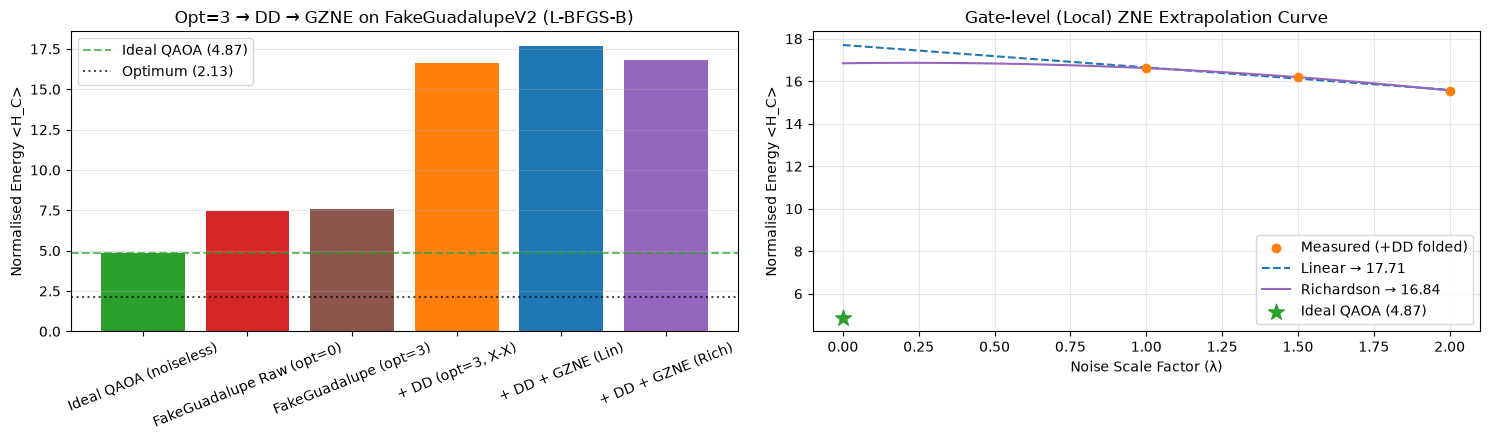

In [47]:
from qiskit.circuit.library import XGate
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDelay, PadDynamicalDecoupling
from qiskit_ibm_runtime.fake_provider import FakeGuadalupeV2
from qiskit_mitigation.zne import GateFoldingPass

EVAL_SHOTS = 256                 # shots per circuit evaluation on FakeGuadalupeV2 GPU
SCALE_FACTORS = [1.0, 1.5, 2.0]  # fractional gate folding avoids full depolarization at depth ~500

# 1. Pick the best converged Ideal parameters (avoids optimizer-budget confound)
best_opt = min(ideal_results, key=lambda k: ideal_results[k]["energy"])
best_params = ideal_results[best_opt]["result"].x
ev_ideal = ideal_results[best_opt]["energy"]
print(f"Evaluating best Ideal circuit ({best_opt}, Ideal <H_C> = {ev_ideal:.4f}) on FakeGuadalupeV2...")

# 2. Transpile bound circuit to FakeGuadalupeV2: Raw (opt=0) vs Transpilation Optimization (opt=3)
fake_backend = FakeGuadalupeV2()
bound_ideal = ideal_ansatz.assign_parameters(best_params)

delay_pm = PassManager([
    ALAPScheduleAnalysis(target=fake_backend.target),
    PadDelay(target=fake_backend.target),
])
dd_pm = PassManager([
    ALAPScheduleAnalysis(target=fake_backend.target),
    PadDynamicalDecoupling(target=fake_backend.target, dd_sequence=[XGate(), XGate()], pulse_alignment=1),
])

isa_opt0 = transpile(bound_ideal, backend=fake_backend, optimization_level=0, seed_transpiler=42)
isa_obs_opt0 = cost_hamiltonian.apply_layout(isa_opt0.layout)
raw_opt0_sched = delay_pm.run(isa_opt0)

isa_opt3 = transpile(bound_ideal, backend=fake_backend, optimization_level=3, seed_transpiler=42)
isa_obs_opt3 = cost_hamiltonian.apply_layout(isa_opt3.layout)
opt3_sched = delay_pm.run(isa_opt3)

# 3. Error Suppression: Dynamical Decoupling (ALAP scheduling + X-X pulses on opt=3 circuit)
dd_circ = dd_pm.run(isa_opt3)
print(f"Raw (opt=0, ALAP) : depth={raw_opt0_sched.depth()}, ops={dict(raw_opt0_sched.count_ops())}")
print(f"Opt=3 (ALAP)      : depth={opt3_sched.depth()}, ops={dict(opt3_sched.count_ops())}")
print(f"+ DD (opt=3, X-X) : depth={dd_circ.depth()}, ops={dict(dd_circ.count_ops())}")

# 4. GPU-backed AerEstimator with FakeGuadalupeV2 noise model (VRAM-safe single precision + chunked shots)
fb_noise_model = NoiseModel.from_backend(fake_backend)
fb_device = "GPU" if "GPU" in AerSimulator().available_devices() else "CPU"
fb_backend_opts = {"method": "statevector", "device": fb_device, "noise_model": fb_noise_model}
if fb_device == "GPU":
    fb_backend_opts.update({
        "precision": "single",
        "cuStateVec_enable": True,
        "batched_shots_gpu": True,
        "max_shot_size": 256,
    })

fb_estimator = AerEstimator(
    options={
        "backend_options": fb_backend_opts,
        "run_options": {"shots": EVAL_SHOTS, "seed_simulator": 42},
    }
)

def eval_fb(circ, obs, label: str) -> float:
    t0 = time.perf_counter()
    ev = float(fb_estimator.run([(circ, obs)]).result()[0].data.evs)
    print(f"  {label:<26} <H_C> = {ev:8.4f}  ({time.perf_counter() - t0:.1f} s)")
    return ev

# 5. Run Raw (opt=0) -> Opt=3 -> DD -> DD + GZNE (reusing DD as scale factor 1.0)
ev_raw_opt0 = eval_fb(raw_opt0_sched, isa_obs_opt0, "FakeGuadalupe Raw (opt=0)")
ev_opt3 = eval_fb(opt3_sched, isa_obs_opt3, "FakeGuadalupe (opt=3)")
zne_evs = []
for sf in SCALE_FACTORS:
    circ_sf = dd_circ if sf == 1.0 else GateFoldingPass(noise_factor=sf, seed=42)(dd_circ)
    lbl = "+ DD (lambda=1.0)" if sf == 1.0 else f"+ DD Fold (lambda={sf:.1f})"
    zne_evs.append(eval_fb(circ_sf, isa_obs_opt3, lbl))

ev_dd = zne_evs[0]
lin_coeffs = np.polyfit(SCALE_FACTORS, zne_evs, deg=1)
ev_gzne_lin = float(np.polyval(lin_coeffs, 0.0))
rich_coeffs = np.polyfit(SCALE_FACTORS, zne_evs, deg=min(2, len(SCALE_FACTORS) - 1))
ev_gzne_rich = float(np.polyval(rich_coeffs, 0.0))

# 6. Summary table
dd_gzne_summary = {
    "Ideal QAOA (noiseless)": ev_ideal,
    "FakeGuadalupe Raw (opt=0)": ev_raw_opt0,
    "FakeGuadalupe (opt=3)": ev_opt3,
    "+ DD (opt=3, X-X)": ev_dd,
    "+ DD + GZNE (Lin)": ev_gzne_lin,
    "+ DD + GZNE (Rich)": ev_gzne_rich,
}
print("\n" + f"{'Stage':<26} {'<H_C>':>9} {'|Err vs Ideal|':>15}")
print("-" * 52)
for stage, val in dd_gzne_summary.items():
    print(f"{stage:<26} {val:>9.4f} {abs(val - ev_ideal):>15.4f}")

# 7. Plot stage comparison + ZNE extrapolation curve
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

stages = list(dd_gzne_summary.keys())
vals = list(dd_gzne_summary.values())
colors = ["tab:green", "tab:red", "tab:brown", "tab:orange", "tab:blue", "tab:purple"]
axes[0].bar(stages, vals, color=colors)
axes[0].axhline(ev_ideal, color="tab:green", linestyle="--", alpha=0.7, label=f"Ideal QAOA ({ev_ideal:.2f})")
axes[0].axhline(opt_energy, color="black", linestyle=":", alpha=0.7, label=f"Optimum ({opt_energy:.2f})")
axes[0].set_title(f"Opt=3 → DD → GZNE on FakeGuadalupeV2 ({best_opt})")
axes[0].set_ylabel("Normalised Energy <H_C>")
axes[0].tick_params(axis="x", rotation=22)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

x_grid = np.linspace(0.0, max(SCALE_FACTORS), 100)
axes[1].scatter(SCALE_FACTORS, zne_evs, color="tab:orange", zorder=5, label="Measured (+DD folded)")
axes[1].plot(x_grid, np.polyval(lin_coeffs, x_grid), "--", color="tab:blue", label=f"Linear → {ev_gzne_lin:.2f}")
axes[1].plot(x_grid, np.polyval(rich_coeffs, x_grid), "-", color="tab:purple", label=f"Richardson → {ev_gzne_rich:.2f}")
axes[1].scatter([0.0], [ev_ideal], color="tab:green", marker="*", s=140, zorder=6, label=f"Ideal QAOA ({ev_ideal:.2f})")
axes[1].set_title("Gate-level (Local) ZNE Extrapolation Curve")
axes[1].set_xlabel("Noise Scale Factor (λ)")
axes[1].set_ylabel("Normalised Energy <H_C>")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()